# Exploración y diagnóstico del conjunto de datos
**Unidad II · Actividad de Evaluación 1 · Recursamiento ECBD 2026**

**Alumno:** Ulises González Coronado  
**Institución:** Universidad Tecnológica de Tula-Tepeji  
**Docente:** Ing. José Luis Herrera Gallardo  
**Proyecto:** Evaluación de eficiencia energética de edificios  
**Elaboración:** 7 de noviembre de 2026. Esta fecha identifica esta evidencia, no acredita una entrega anterior.

**Pregunta:** ¿Cómo cambian las cargas de calefacción y refrigeración entre edificios con distinta compacidad relativa y altura total?

Este notebook diagnostica el Excel original. No ejecuta el ETL, no imputa, no elimina filas y no guarda cambios en el dataset. Los tratamientos solo se proponen para después. Ejecuta las celdas de arriba hacia abajo.

**Actualización del notebook: 10 de noviembre de 2026.** Se incorporan medidas centrales con todas las modas, gráficas de tres variables y tres propuestas de análisis. Se conserva el diagnóstico existente.

## 1. Entorno, identificación y procedencia
Energy Efficiency, de Tsanas y Xifara (2012), procede de UCI Machine Learning Repository. Se recibe en formato Excel `.xlsx`, archivo `ENB2012_data.xlsx`.

Contiene configuraciones simuladas de edificios y dos respuestas: Y1 (calefacción) y Y2 (refrigeración). Son **datos estructurados**, organizados en filas y columnas; proceden de simulación computacional, no de transacciones, redes sociales ni sensores de edificios reales.

Fuente: https://archive.ics.uci.edu/dataset/242/energy+efficiency  
Identificador: https://doi.org/10.24432/C51307  
Licencia declarada en los documentos del proyecto: CC BY 4.0.

Las unidades físicas no se asignan sin respaldo documental. Se conserva la escala original; X1 es una razón y X7 una proporción. Los códigos X6 y X8 no se convierten en direcciones cardinales sin documentación.

In [1]:
from pathlib import Path
import hashlib
import sys
import platform
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Encuentra la raíz tanto si Jupyter se abre en la raíz como en notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/ENB2012_data.xlsx").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abre Jupyter dentro de la carpeta del proyecto.")
archivo = ROOT / "data/raw/ENB2012_data.xlsx"
firma_inicial = hashlib.sha256(archivo.read_bytes()).hexdigest()
df = pd.read_excel(archivo, engine="openpyxl")
print("Python:", platform.python_version())
print("Intérprete:", sys.executable)
print("Pandas:", pd.__version__)
print("Archivo:", archivo.name)
print("SHA-256:", firma_inicial)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.2
Intérprete: C:\Users\DELL\Desktop\RecurseExtracciónBD\REC_ECBD_2026_Gonzalez_Ulises\.venv\Scripts\python.exe
Pandas: 2.3.3
Archivo: ENB2012_data.xlsx
SHA-256: 0089fcffc1415e41e2ff63730cca5280efe54fc43d722dfde1b0aaa808e35dc4


**Interpretación.** `read_excel()` carga el archivo en un DataFrame, que es una tabla en memoria. La ruta del intérprete permite identificar el entorno que está ejecutando el notebook. La firma se volverá a calcular al final para comprobar que el archivo original no cambió.

## 2. Carga y exploración inicial

In [2]:
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


**Interpretación de `head()`.** Muestra las primeras cinco simulaciones. Las columnas X1–X8 describen el diseño y Y1–Y2 son las respuestas. La vista previa sirve para reconocer la organización, pero no permite diagnosticar por sí sola todas las filas.

In [3]:
df.shape

(768, 10)

**Interpretación de `shape`.** El resultado `(768, 10)` indica 768 registros y 10 variables: ocho entradas y dos respuestas. No representa 768 edificios reales medidos, sino escenarios simulados.

In [4]:
df.columns

Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')

**Interpretación de `columns`.** Los nombres son X1, X2, X3, X4, X5, X6, X7, X8, Y1 y Y2. No hay que confundir Y1 y Y2 con años. Se conservarán estos nombres para mantener la trazabilidad con la fuente.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


**Interpretación de `info()`.** Las diez columnas tienen 768 valores no nulos. Ocho se cargan como `float64` y dos como `int64`. La información de memoria describe la tabla cargada, no el tamaño del Excel. No hay fechas ni columnas de texto.

In [6]:
df.dtypes

X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object

**Interpretación de `dtypes`.** X6 y X8 están almacenadas como enteros; las otras variables como decimales. El tipo informático no determina el significado estadístico: orientación y distribución son cualitativas nominales aunque se representen mediante números.

In [7]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


**Interpretación de `describe()`.** Resume cantidad, media, dispersión y cuartiles. La calefacción varía de 6.01 a 43.10 y la refrigeración de 10.90 a 48.03. Las medias de códigos como X6 o X8 no describen una orientación o distribución promedio con significado físico; esas variables se examinan mediante frecuencias.

## 3. Diccionario y clasificación de las variables
Se distinguen el tipo de almacenamiento y la naturaleza de la variable. Una magnitud continua puede tener pocos niveles observados en un experimento: X5 solo tiene 3.5 y 7 y X7 tiene cuatro proporciones, pero no se convierten por ello en códigos nominales.

In [8]:
# El diccionario documenta; no altera las columnas del dataset.
variables = [('X1', 'Compacidad relativa', 'Cuantitativa', 'Continua', 'Adimensional', 'Comparación principal del diseño'), ('X2', 'Área de superficie', 'Cuantitativa', 'Continua', 'No confirmada en archivos aportados', 'Apoyo geométrico y predicción'), ('X3', 'Área de muros', 'Cuantitativa', 'Continua', 'No confirmada en archivos aportados', 'Relación entre envolvente y cargas'), ('X4', 'Área del techo', 'Cuantitativa', 'Continua', 'No confirmada en archivos aportados', 'Comparación geométrica'), ('X5', 'Altura total', 'Cuantitativa', 'Continua; dos niveles observados', 'No confirmada en archivos aportados', 'Comparación principal por altura'), ('X6', 'Orientación', 'Cualitativa', 'Nominal codificada', 'Código sin unidad', 'Comparar frecuencias; codificación posterior'), ('X7', 'Área de acristalamiento', 'Cuantitativa', 'Continua; cuatro niveles observados', 'Proporción adimensional', 'Explorar efecto asociado del acristalamiento'), ('X8', 'Distribución del acristalamiento', 'Cualitativa', 'Nominal codificada', 'Código sin unidad', 'Comparar configuraciones; codificación posterior'), ('Y1', 'Carga de calefacción', 'Cuantitativa', 'Continua', 'Escala original; unidad no confirmada', 'Objetivo de regresión y base de clase didáctica'), ('Y2', 'Carga de refrigeración', 'Cuantitativa', 'Continua', 'Escala original; unidad no confirmada', 'Objetivo de regresión y comparación de cargas')]
diccionario = pd.DataFrame(variables, columns=["Variable", "Descripción", "Naturaleza",
                                                "Clasificación", "Unidad", "Utilidad"])
diccionario.insert(2, "Tipo Python/Pandas", [str(df[v].dtype) for v in diccionario.Variable])
display(diccionario)

,Variable,Descripción,Tipo Python/Pandas,Naturaleza,Clasificación,Unidad,Utilidad
0,X1,Compacidad relativa,float64,Cuantitativa,Continua,Adimensional,Comparación principal del diseño
1,X2,Área de superficie,float64,Cuantitativa,Continua,No confirmada en archivos aportados,Apoyo geométrico y predicción
2,X3,Área de muros,float64,Cuantitativa,Continua,No confirmada en archivos aportados,Relación entre envolvente y cargas
3,X4,Área del techo,float64,Cuantitativa,Continua,No confirmada en archivos aportados,Comparación geométrica
4,X5,Altura total,float64,Cuantitativa,Continua; dos niveles observados,No confirmada en archivos aportados,Comparación principal por altura
5,X6,Orientación,int64,Cualitativa,Nominal codificada,Código sin unidad,Comparar frecuencias; codificación posterior
6,X7,Área de acristalamiento,float64,Cuantitativa,Continua; cuatro niveles observados,Proporción adimensional,Explorar efecto asociado del acristalamiento
7,X8,Distribución del acristalamiento,int64,Cualitativa,Nominal codificada,Código sin unidad,Comparar configuraciones; codificación posterior
8,Y1,Carga de calefacción,float64,Cuantitativa,Continua,Escala original; unidad no confirmada,Objetivo de regresión y base de clase didáctica
9,Y2,Carga de refrigeración,float64,Cuantitativa,Continua,Escala original; unidad no confirmada,Objetivo de regresión y comparación de cargas


**Interpretación.** Hay ocho magnitudes cuantitativas continuas y dos variables cualitativas nominales codificadas. Ninguna columna original es fecha, identificador ni variable binaria. Las futuras clases alta/baja serían una variable derivada, no una columna original.

## 4. Diagnóstico de calidad
### 4.1 Valores faltantes

In [9]:
faltantes = pd.DataFrame({"Cantidad": df.isnull().sum(),
                          "Porcentaje": df.isnull().mean().mul(100)})
display(faltantes)
print("Total faltante:", int(faltantes.Cantidad.sum()))

,Cantidad,Porcentaje
X1,0,0.0
X2,0,0.0
X3,0,0.0
X4,0,0.0
X5,0,0.0
X6,0,0.0
X7,0,0.0
X8,0,0.0
Y1,0,0.0
Y2,0,0.0


Total faltante: 0


**Interpretación y propuesta.** Las diez variables presentan 0 faltantes y 0 %. No se necesita imputar en este archivo. Si llegaran nuevas observaciones incompletas, se revisaría su origen antes de decidir; los predictores podrían imputarse dentro del entrenamiento y los objetivos ausentes requerirían revisión, sin inventar etiquetas para evaluar.

### 4.2 Registros duplicados

In [10]:
print("Duplicados completos:", int(df.duplicated().sum()))
print("Entradas X1-X8 repetidas:", int(df.duplicated(subset=[f"X{i}" for i in range(1,9)]).sum()))
print("Combinaciones geométricas X1-X5:", df[[f"X{i}" for i in range(1,6)]].drop_duplicates().shape[0])
# drop_duplicates() se aplica a una vista para contar; no reemplaza ni limpia df.
display(df.groupby(["X1", "X5"]).size().rename("Simulaciones").reset_index())

Duplicados completos: 0
Entradas X1-X8 repetidas: 0
Combinaciones geométricas X1-X5: 12


,X1,X5,Simulaciones
0,0.62,3.5,64
1,0.64,3.5,64
2,0.66,3.5,64
3,0.69,3.5,64
4,0.71,3.5,64
5,0.74,3.5,64
6,0.76,7.0,64
7,0.79,7.0,64
8,0.82,7.0,64
9,0.86,7.0,64


**Interpretación y propuesta.** No hay duplicados completos ni entradas X1–X8 repetidas. Hay 12 geometrías y cada una tiene 64 variantes; compartir geometría no es duplicación porque cambian orientación o acristalamiento. Una duplicación inesperada podría surgir de una importación repetida; se comprobaría su procedencia antes de decidir su eliminación en una etapa posterior.

### 4.3 Inconsistencias, tipos y categorías

In [11]:
magnitudes_positivas = ["X1", "X2", "X3", "X4", "X5", "Y1", "Y2"]
controles = pd.Series({
    "Nombres u orden de columnas inesperados": int(df.columns.tolist() != [f"X{i}" for i in range(1,9)] + ["Y1", "Y2"]),
    "Columnas no numéricas": int(sum(not pd.api.types.is_numeric_dtype(t) for t in df.dtypes)),
    "Valores infinitos": int(np.isinf(df.select_dtypes(include="number").to_numpy()).sum()),
    "Magnitudes no positivas": int((df[magnitudes_positivas] <= 0).sum().sum()),
    "Compacidad fuera de (0, 1]": int(((df.X1 <= 0) | (df.X1 > 1)).sum()),
    "Acristalamiento fuera de [0, 1]": int((~df.X7.between(0,1)).sum()),
    "Orientación fuera de códigos observados documentados": int((~df.X6.isin([2,3,4,5])).sum()),
    "Distribución fuera de códigos observados documentados": int((~df.X8.isin([0,1,2,3,4,5])).sum()),
    "Sin cristal y distribución distinta de cero": int(((df.X7 == 0) & (df.X8 != 0)).sum()),
    "Con cristal y distribución cero": int(((df.X7 > 0) & (df.X8 == 0)).sum())
}, name="Incidencias")
display(controles.to_frame())
display(pd.DataFrame({"Mínimo": df.min(), "Máximo": df.max(), "Valores distintos": df.nunique()}))
for v in ["X5", "X6", "X7", "X8"]:
    print(v, df[v].value_counts().sort_index().to_dict())

,Incidencias
Nombres u orden de columnas inesperados,0
Columnas no numéricas,0
Valores infinitos,0
Magnitudes no positivas,0
"Compacidad fuera de (0, 1]",0
"Acristalamiento fuera de [0, 1]",0
Orientación fuera de códigos observados documentados,0
Distribución fuera de códigos observados documentados,0
Sin cristal y distribución distinta de cero,0
Con cristal y distribución cero,0


,Mínimo,Máximo,Valores distintos
X1,0.62,0.98,12
X2,514.50,808.50,12
X3,245.00,416.50,7
X4,110.25,220.50,4
X5,3.50,7.00,2
X6,2.00,5.00,4
X7,0.00,0.40,4
X8,0.00,5.00,6
Y1,6.01,43.10,587
Y2,10.90,48.03,636


X5 {3.5: 384, 7.0: 384}
X6 {2: 192, 3: 192, 4: 192, 5: 192}
X7 {0.0: 48, 0.1: 240, 0.25: 240, 0.4: 240}
X8 {0: 48, 1: 144, 2: 144, 3: 144, 4: 144, 5: 144}


**Interpretación.** Todos los controles devuelven cero incidencias. Los rangos observados son descripciones del archivo, no límites universales. Las reglas de X7 y X8 son comprobaciones de coherencia para el conjunto recibido. No se identifican errores de fechas porque el dataset no contiene fechas. La ausencia de incidencias bajo estas reglas no demuestra que las simulaciones estén libres de cualquier error posible.

## 5. Análisis estadístico inicial

In [12]:
seleccionadas = ["X1", "X5", "Y1", "Y2"]
estadisticas = df[seleccionadas].agg(["mean", "median", "min", "max", "std"]).T
estadisticas.columns = ["Media", "Mediana", "Mínimo", "Máximo", "Desviación estándar"]
display(estadisticas.round(4))
display(df.groupby("X5")[["Y1", "Y2"]].agg(["count", "mean", "median", "std"]).round(4))
print("Compacidades compartidas entre alturas:", int((df.groupby("X1").X5.nunique() > 1).sum()))

,Media,Mediana,Mínimo,Máximo,Desviación estándar
X1,0.7642,0.75,0.62,0.98,0.1058
X5,5.2500,5.25,3.50,7.00,1.7511
Y1,22.3072,18.95,6.01,43.10,10.0902
Y2,24.5878,22.08,10.90,48.03,9.5133


Y1                             Y2                         
    count     mean  median     std count     mean  median     std
X5                                                               
3.5   384  13.3385  12.985  2.6718   384  16.0714  15.610  2.4208
7.0   384  31.2759  31.675  5.9546   384  33.1041  33.135  5.4724

Compacidades compartidas entre alturas: 0


**Interpretación.** La compacidad media es 0.7642, con desviación 0.1058. La altura media y mediana son 5.25, aunque no existe una observación de altura 5.25: es el punto intermedio entre los dos niveles. Y1 tiene media 22.3072 y mediana 18.95; Y2 tiene media 24.5878 y mediana 22.08. La desviación de 10.0902 en Y1 y 9.5133 en Y2 muestra dispersión entre escenarios.

Por altura, las medias Y1/Y2 son 13.34/16.07 para 3.5 y 31.28/33.10 para 7. No hay compacidades compartidas entre las dos alturas; las diferencias describen configuraciones completas y no el efecto aislado de altura o compacidad.

### 5.1 Media, mediana y moda en tres variables

Se comparan **X1 (compacidad), Y1 (calefacción) y Y2 (refrigeración)**. La media utiliza todos los valores, la mediana divide los datos ordenados en dos mitades y la moda identifica los valores exactos más frecuentes. Se conservan **todas las modas empatadas**. Las tres variables se muestran en paneles con sus propias escalas porque compacidad y cargas no se pueden comparar como magnitudes equivalentes.

La moda se calcula antes de redondear; en variables continuas depende de la precisión con la que se registraron los datos. Una barra alta del histograma representa un intervalo frecuente, no necesariamente la moda exacta.

In [13]:
variables_centrales = ["X1", "Y1", "Y2"]
nombres_centrales = {"X1": "Compacidad relativa", "Y1": "Carga de calefacción",
                     "Y2": "Carga de refrigeración"}
colores_centrales = {"X1": "#5578a4", "Y1": "#217c72", "Y2": "#d38a3a"}
resumen_central = []
modas_centrales = {}
for v in variables_centrales:
    serie = df[v].dropna()
    modas_centrales[v] = serie.mode().to_numpy()
    frecuencia = int(serie.value_counts().max())
    resumen_central.append({
        "Variable": v, "Descripción": nombres_centrales[v],
        "Media": serie.mean(), "Mediana": serie.median(),
        "Moda(s) exacta(s)": ", ".join(f"{x:g}" for x in modas_centrales[v]),
        "Número de modas": len(modas_centrales[v]),
        "Frecuencia de cada moda": frecuencia,
        "% por cada moda": 100 * frecuencia / len(serie),
        "Mínimo": serie.min(), "Máximo": serie.max(),
        "Desviación estándar": serie.std(ddof=1)
    })
resumen_central = pd.DataFrame(resumen_central).set_index("Variable")
display(resumen_central.round(4))

,Descripción,Media,Mediana,Moda(s) exacta(s),Número de modas,Frecuencia de cada moda,% por cada moda,Mínimo,Máximo,Desviación estándar
Variable,,,,,,,,,,
X1,Compacidad relativa,0.7642,0.75,"0.62, 0.64, 0.66, 0.69, 0.71, 0.74, 0.76, 0.79...",12,64,8.3333,0.62,0.98,0.1058
Y1,Carga de calefacción,22.3072,18.95,15.16,1,6,0.7812,6.01,43.10,10.0902
Y2,Carga de refrigeración,24.5878,22.08,"14.27, 14.28, 17.2, 21.33, 29.79",5,4,0.5208,10.90,48.03,9.5133


**Interpretación de la tabla.** X1 tiene media **0.7642** y mediana **0.75**. Sus doce valores son igualmente frecuentes: cada uno aparece 64 veces (8.33 %), por lo que **no existe una moda única**. Y1 tiene media **22.3072**, mediana **18.95** y moda **15.16**, con seis apariciones (0.78 %). Y2 tiene media **24.5878**, mediana **22.08** y cinco modas: **14.27, 14.28, 17.20, 21.33 y 29.79**, con cuatro apariciones cada una (0.52 %). Las modas de las cargas concentran muy pocas observaciones; no describen por sí solas un diseño típico.

En Y1 y Y2 la media supera a la mediana. Los escenarios de mayor carga elevan el promedio, pero esa diferencia no basta para afirmar una forma específica de distribución. La desviación estándar de la tabla es muestral (`ddof=1`).

### 5.2 Gráficas de media, mediana y moda
Los histogramas muestran la distribución de cada variable y las líneas ubican sus medidas centrales. En X1 todos los niveles están empatados; en Y2 se marcan sus cinco modas.

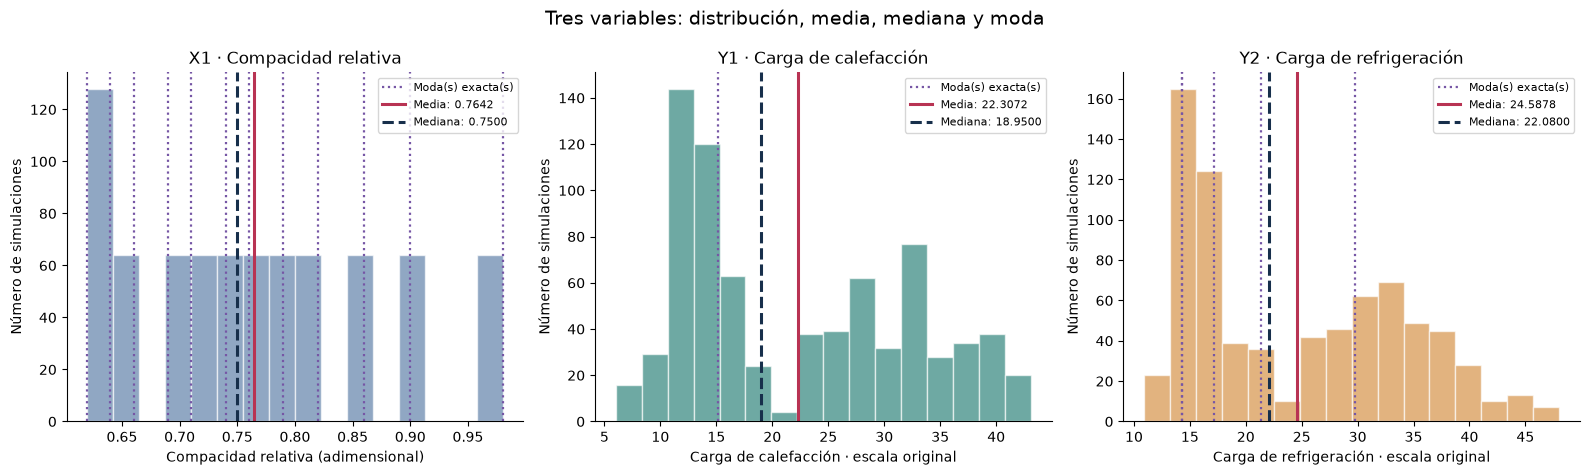

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, v in zip(axes, variables_centrales):
    ax.hist(df[v], bins=16, color=colores_centrales[v], alpha=0.65,
            edgecolor="white")
    for j, valor in enumerate(modas_centrales[v]):
        ax.axvline(valor, color="#7656a5", linestyle=":", linewidth=1.6,
                   label="Moda(s) exacta(s)" if j == 0 else None)
    ax.axvline(df[v].mean(), color="#b83353", linewidth=2.2,
               label=f"Media: {df[v].mean():.4f}")
    ax.axvline(df[v].median(), color="#172f4b", linestyle="--", linewidth=2.2,
               label=f"Mediana: {df[v].median():.4f}")
    ax.set(title=f"{v} · {nombres_centrales[v]}",
           xlabel="Compacidad relativa (adimensional)" if v == "X1"
                  else f"{nombres_centrales[v]} · escala original",
           ylabel="Número de simulaciones")
    ax.legend(fontsize=8)
fig.suptitle("Tres variables: distribución, media, mediana y moda", fontsize=14)
fig.tight_layout()
plt.show()

**Interpretación por panel.** En **X1**, las doce líneas de moda corresponden al mismo número de simulaciones por nivel; la media no necesita coincidir con un valor observado. En **Y1**, la moda 15.16 y la mediana 18.95 quedan por debajo de la media 22.31: el promedio resume escenarios con demandas diferentes. En **Y2**, las cinco líneas de moda reflejan empates dispersos, mientras que mediana y media se ubican en 22.08 y 24.59. Las frecuencias de los histogramas se agrupan en intervalos; las modas marcadas proceden del conteo de valores exactos.

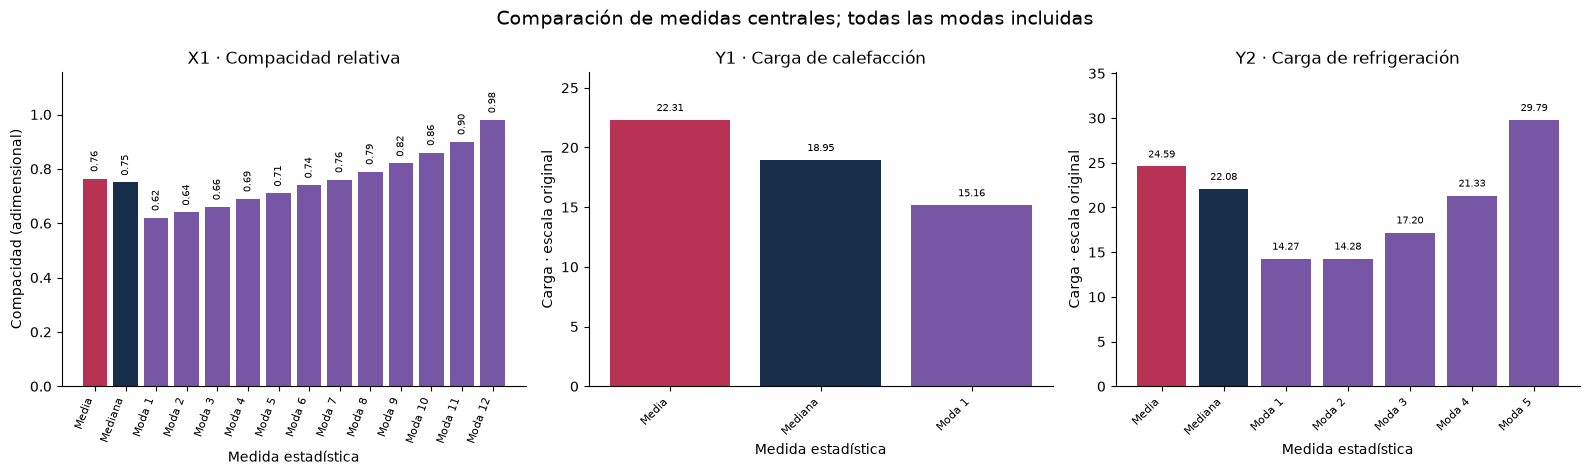

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, v in zip(axes, variables_centrales):
    modos = modas_centrales[v]
    posiciones = np.arange(2 + len(modos))
    valores = [df[v].mean(), df[v].median(), *modos]
    etiquetas = ["Media", "Mediana"] + [f"Moda {i+1}" for i in range(len(modos))]
    ax.bar(posiciones, valores, color=["#b83353", "#172f4b"] + ["#7656a5"] * len(modos))
    ax.set_xticks(posiciones)
    ax.set_xticklabels(etiquetas, rotation=70 if len(modos) > 5 else 45, ha="right", fontsize=8)
    ax.set(title=f"{v} · {nombres_centrales[v]}", xlabel="Medida estadística",
           ylabel="Compacidad (adimensional)" if v == "X1" else "Carga · escala original")
    ax.set_ylim(0, max(valores) * 1.18)
    for x, valor in zip(posiciones, valores):
        ax.text(x, valor + max(valores)*0.025, f"{valor:.2f}", ha="center", va="bottom",
                fontsize=7, rotation=90 if len(modos) > 5 else 0)
fig.suptitle("Comparación de medidas centrales; todas las modas incluidas", fontsize=14)
fig.tight_layout()
plt.show()

**Interpretación de las barras.** Cada panel permite comparar directamente las medidas de una misma variable. En X1 las doce barras de moda son niveles igualmente frecuentes, no doce grupos con diferente frecuencia. En Y1 hay una moda y en Y2 cinco. La altura de estas barras representa **el valor de la medida**, no su frecuencia. Los paneles tienen escalas distintas; no se comparan las alturas de barras entre X1 y las cargas.

## 6. Detección inicial de valores atípicos
Se utiliza la regla exploratoria de Tukey: límites Q1 − 1.5×IQR y Q3 + 1.5×IQR, donde IQR = Q3 − Q1. Se examina cada variable por separado, sin eliminar observaciones.

,Q1,Q3,IQR,Límite inferior,Límite superior,Señalados,Porcentaje
X1,0.6825,0.8300,0.1475,0.4613,1.0512,0,0.0
X5,3.5000,7.0000,3.5000,-1.7500,12.2500,0,0.0
Y1,12.9925,31.6675,18.6750,-15.0200,59.6800,0,0.0
Y2,15.6200,33.1325,17.5125,-10.6487,59.4012,0,0.0


C:\Users\DELL\AppData\Local\Temp\ipykernel_96408\3145167608.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[v], vert=False)
C:\Users\DELL\AppData\Local\Temp\ipykernel_96408\3145167608.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[v], vert=False)
C:\Users\DELL\AppData\Local\Temp\ipykernel_96408\3145167608.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[v], vert=False)
C:\Users\DELL\AppData\Local\Temp\ipykernel_96408\3145167608.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.box

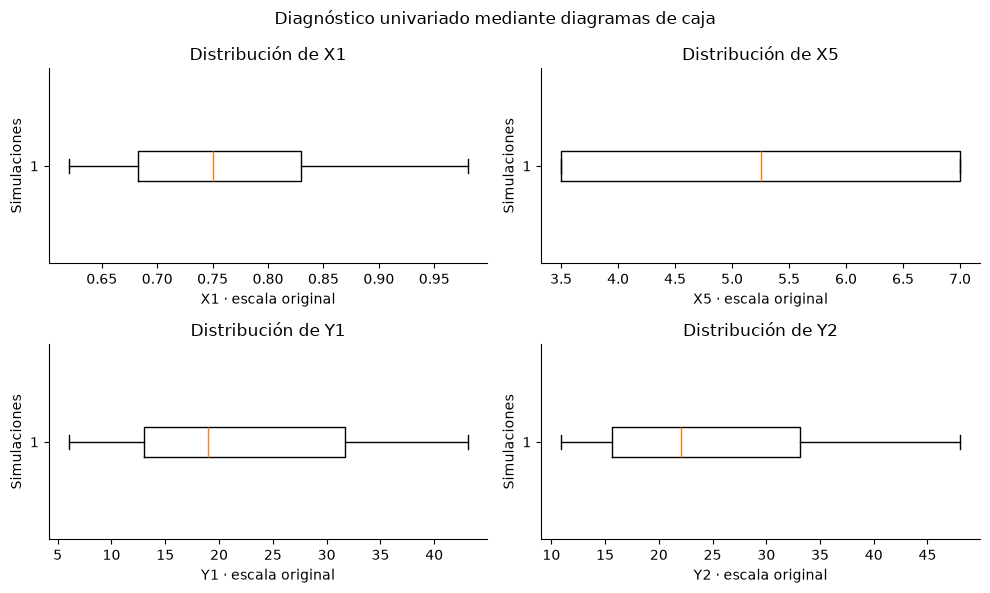

In [16]:
q1 = df[seleccionadas].quantile(0.25)
q3 = df[seleccionadas].quantile(0.75)
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
marcas = df[seleccionadas].lt(inferior) | df[seleccionadas].gt(superior)
atipicos = pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                         "Límite inferior": inferior, "Límite superior": superior,
                         "Señalados": marcas.sum(), "Porcentaje": marcas.mean() * 100})
display(atipicos.round(4))
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, v in zip(axes.flat, seleccionadas):
    ax.boxplot(df[v], vert=False)
    ax.set(title=f"Distribución de {v}", xlabel=f"{v} · escala original", ylabel="Simulaciones")
fig.suptitle("Diagnóstico univariado mediante diagramas de caja")
fig.tight_layout()
plt.show()

**Interpretación por variable.** X1 no presenta señales IQR; su extremo 0.98 pertenece a los diseños disponibles. X5 tampoco presenta señales: sus dos niveles forman parte del diseño experimental. Y1 y Y2 tienen cero señales con los límites calculados y sus máximos no se consideran errores solo por ser elevados. No se propone eliminar ni recortar valores en estas cuatro variables.

Los límites negativos de la regla IQR son umbrales estadísticos, no cargas o alturas físicamente admisibles. Este resultado no descarta anomalías multivariadas o dentro de subgrupos. Si se detectaran después, habría que revisar configuración y procedencia antes de tratarlas.

## 7. Visualizaciones iniciales
Además de los boxplots, se incluyen tres tipos de gráfica. Todas se calculan a partir del Excel cargado.

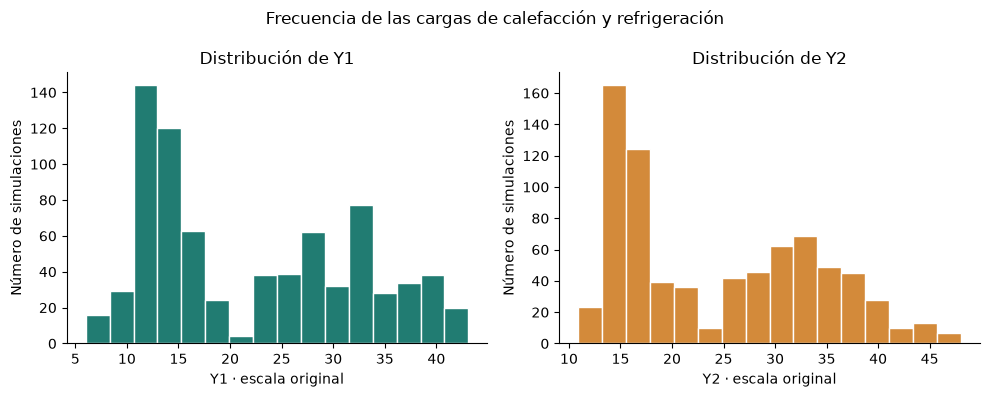

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, v, color in zip(axes, ["Y1", "Y2"], ["#217c72", "#d38a3a"]):
    ax.hist(df[v], bins=16, color=color, edgecolor="white")
    ax.set(title=f"Distribución de {v}", xlabel=f"{v} · escala original", ylabel="Número de simulaciones")
fig.suptitle("Frecuencia de las cargas de calefacción y refrigeración")
fig.tight_layout()
plt.show()

**Interpretación del histograma.** Las cargas se distribuyen en intervalos con distintas frecuencias, compatibles con la mezcla de configuraciones geométricas. La media global no resume por completo esa heterogeneidad. Los intervalos del histograma no son clases energéticas oficiales.

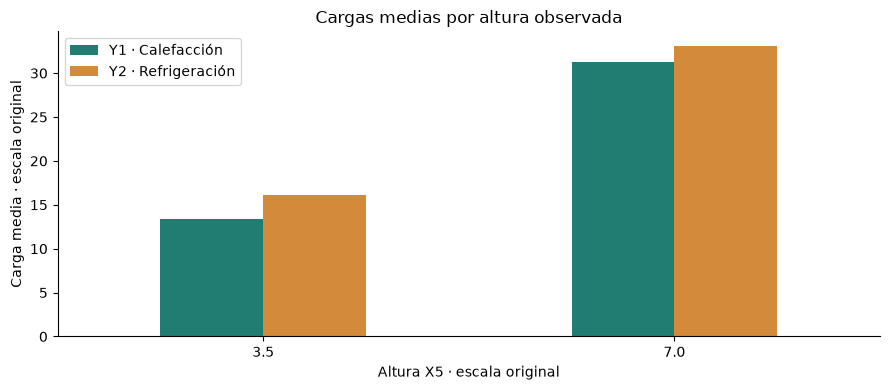

In [18]:
medias_altura = df.groupby("X5")[["Y1", "Y2"]].mean()
ax = medias_altura.plot.bar(color=["#217c72", "#d38a3a"], rot=0, figsize=(9,4))
ax.set(title="Cargas medias por altura observada", xlabel="Altura X5 · escala original",
       ylabel="Carga media · escala original")
ax.legend(["Y1 · Calefacción", "Y2 · Refrigeración"])
plt.tight_layout()
plt.show()

**Interpretación de barras.** Las configuraciones de altura 7 tienen cargas medias mayores que las de altura 3.5 en este archivo. No se concluye que duplicar la altura provoque esa diferencia: también cambian compacidad y otras características geométricas.

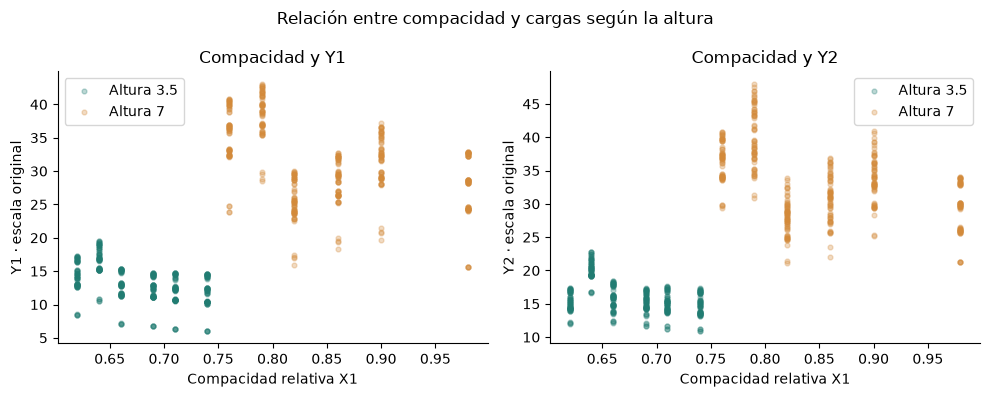

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, objetivo in zip(axes, ["Y1", "Y2"]):
    for altura, color in [(3.5, "#217c72"), (7.0, "#d38a3a")]:
        sub = df.loc[df.X5 == altura]
        ax.scatter(sub.X1, sub[objetivo], s=12, alpha=0.3, color=color, label=f"Altura {altura:g}")
    ax.set(title=f"Compacidad y {objetivo}", xlabel="Compacidad relativa X1", ylabel=f"{objetivo} · escala original")
    ax.legend()
fig.suptitle("Relación entre compacidad y cargas según la altura")
fig.tight_layout()
plt.show()

**Interpretación de dispersión.** Para una misma compacidad hay diferentes cargas, porque también varían orientación y acristalamiento. Los colores ocupan valores distintos de X1: no hay comparación de ambas alturas a compacidad constante. No se aprecia una relación lineal única que deba asumirse para todos los diseños.

### 7.1 Una gráfica con tres variables a la vez: X1, Y1 y Y2
Se utilizan dos ejes para las cargas y una escala de color para la compacidad. Así se relacionan tres variables en una misma visualización sin mezclar sus unidades en un solo eje.

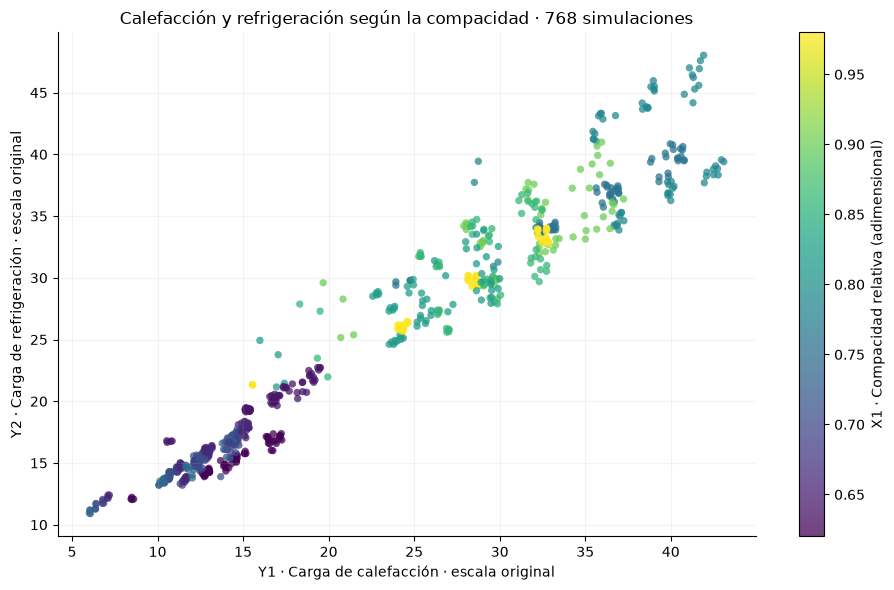

,X1,Y1,Y2
X1,1.0000,0.6223,0.6343
Y1,0.6223,1.0000,0.9759
Y2,0.6343,0.9759,1.0000


In [20]:
fig, ax = plt.subplots(figsize=(9.5, 6))
puntos = ax.scatter(df["Y1"], df["Y2"], c=df["X1"], cmap="viridis",
                    s=28, alpha=0.75, edgecolors="none")
barra_color = fig.colorbar(puntos, ax=ax)
barra_color.set_label("X1 · Compacidad relativa (adimensional)")
ax.set(title="Calefacción y refrigeración según la compacidad · 768 simulaciones",
       xlabel="Y1 · Carga de calefacción · escala original",
       ylabel="Y2 · Carga de refrigeración · escala original")
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()
display(df[variables_centrales].corr().round(4))

**Interpretación.** Los puntos muestran que calefacción y refrigeración tienden a aumentar juntas. El color permite examinar cómo se distribuye la compacidad entre esas combinaciones de cargas. Hay variación para una misma compacidad y la asociación no demuestra causalidad. La tabla complementaria contiene correlaciones de Pearson: mide asociación lineal, no efectos aislados. No se debe usar Y2 como predictor de Y1 si el objetivo del proyecto es predecir ambas cargas a partir del diseño.

### 7.2 Perfiles por compacidad: media y mediana de ambas cargas
Se combinan **X1, Y1 y Y2** para comparar perfiles. La tabla incluye X5 para reconocer la altura asociada a cada compacidad; en este archivo ninguna compacidad está compartida entre ambas alturas.

,Altura_X5,Simulaciones,Media_Y1,Mediana_Y1,Media_Y2,Mediana_Y2
X1,,,,,,
0.62,3.5,64,14.2833,14.335,15.2441,15.105
0.64,3.5,64,16.6153,16.850,20.2272,20.200
0.66,3.5,64,12.8167,12.930,15.8698,15.920
0.69,3.5,64,12.3889,12.570,15.2422,15.295
0.71,3.5,64,12.0401,12.280,15.0355,14.955
0.74,3.5,64,11.8867,12.140,14.8098,14.785
0.76,7.0,64,35.6642,36.440,36.4072,36.860
0.79,7.0,64,38.6080,39.025,40.2394,39.425
0.82,7.0,64,25.5553,25.405,28.0281,28.170


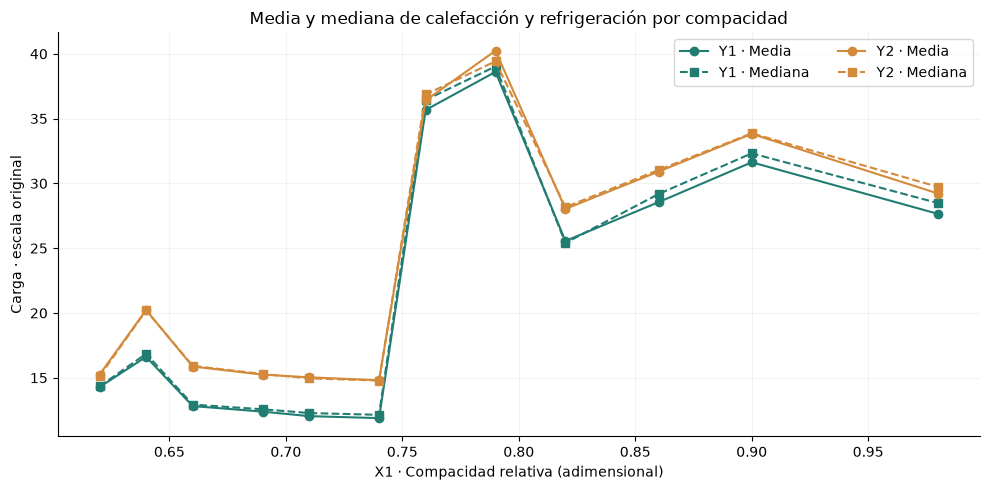

In [21]:
perfiles_compacidad = df.groupby("X1").agg(
    Altura_X5=("X5", "first"), Simulaciones=("Y1", "size"),
    Media_Y1=("Y1", "mean"), Mediana_Y1=("Y1", "median"),
    Media_Y2=("Y2", "mean"), Mediana_Y2=("Y2", "median"))
display(perfiles_compacidad.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
for v, color in [("Y1", "#217c72"), ("Y2", "#d38a3a")]:
    ax.plot(perfiles_compacidad.index, perfiles_compacidad[f"Media_{v}"],
            marker="o", color=color, label=f"{v} · Media")
    ax.plot(perfiles_compacidad.index, perfiles_compacidad[f"Mediana_{v}"],
            marker="s", linestyle="--", color=color, label=f"{v} · Mediana")
ax.set(title="Media y mediana de calefacción y refrigeración por compacidad",
       xlabel="X1 · Compacidad relativa (adimensional)",
       ylabel="Carga · escala original")
ax.legend(ncol=2)
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

**Interpretación.** Cada punto resume las 64 variantes de una compacidad. Las curvas distinguen media y mediana de calefacción y refrigeración; su separación revela que un único promedio no describe toda la variación de los escenarios. Las líneas conectan niveles observados para facilitar la lectura y no son predicciones entre esos niveles. Los cambios reflejan configuraciones completas, porque X1 también está asociado con altura y otras características geométricas.

## 8. Tres propuestas para análisis posteriores

Las tres propuestas responden a la pregunta del proyecto: **¿cómo cambian las cargas de calefacción y refrigeración entre configuraciones con distinta compacidad relativa y altura?** Son planes de trabajo; este notebook presenta el diagnóstico y no entrena modelos.

### Propuesta 1. Regresión: predecir la carga de calefacción

| Elemento | Propuesta |
|---|---|
| Objetivo numérico | **Y1**, carga de calefacción. Repetir el análisis con Y2 como objetivo adicional. |
| Entradas | **X1–X8**. X1 y X5 son centrales; X2–X4 describen geometría, X6 orientación y X7–X8 acristalamiento. |
| Pregunta concreta | ¿Qué carga podría tener una configuración de diseño dentro del ámbito de estas simulaciones? |
| Preparación posterior | Codificar X6 y X8 como nominales; escalar magnitudes cuando el modelo lo requiera; revisar redundancia geométrica. |
| Modelos candidatos | Regresión lineal como referencia y Random Forest como alternativa no lineal. |
| Evaluación | MAE, RMSE y R²; comparar también con una predicción constante ajustada en entrenamiento. |

**Justificación.** Permitiría comparar las cargas esperadas de diferentes configuraciones y estudiar el aporte predictivo de compacidad y altura. Reservar geometrías completas para prueba, manteniendo sus variantes en una sola partición. Ajustar transformaciones únicamente con entrenamiento. No incluir Y1, Y2, identificadores o clases derivadas entre las entradas. La predicción no demuestra causalidad ni ahorros reales.

### Propuesta 2. Clasificación: distinguir carga baja y alta

| Elemento | Propuesta |
|---|---|
| Objetivo | Variable derivada **clase_calefaccion**. No forma parte del Excel original. |
| Clases didácticas | **Baja** si Y1 < 25; **Alta** si Y1 ≥ 25. El corte requiere revisión con el docente. |
| Entradas | X1–X8, con atención a X1 y X5 para relacionar resultados con la pregunta principal. |
| Preparación posterior | Construir la etiqueta en una copia de trabajo; codificar nominales y aplicar escalado si procede. |
| Modelos candidatos | Regresión logística o árbol de decisión. |
| Evaluación | Matriz de confusión, precisión, sensibilidad y F1 macro; comparar con la clase mayoritaria y revisar equilibrio de clases. |

**Justificación.** Facilitaría reconocer diseños asociados a cargas altas o bajas en estas simulaciones. **No es una certificación energética** ni una norma de eficiencia. Y1 no debe emplearse como predictor porque define la etiqueta; Y2 tampoco se propone como entrada. Mantener geometrías separadas entre entrenamiento y prueba para evitar que sus variantes eleven artificialmente el resultado.

### Propuesta 3. Agrupamiento: identificar perfiles de diseño

| Elemento | Propuesta |
|---|---|
| Objetivo | Encontrar configuraciones similares sin etiquetas previas. |
| Variables iniciales | X1–X5 y X7: compacidad, superficies, altura y proporción acristalada. |
| Categorías opcionales | Incorporar X6 y X8 mediante codificación nominal si ayudan a interpretar perfiles. |
| Preparación posterior | Revisar redundancia de superficies y compacidad; estandarizar magnitudes y revisar el peso de las variables. |
| Técnica candidata | K-means como punto inicial; comparar varios números de grupos y su estabilidad. |
| Evaluación e interpretación | Silhouette, tamaño y estabilidad de grupos; perfiles de variables originales y sus cargas. |

**Justificación.** Ayudaría a reconocer perfiles geométricos y de acristalamiento relacionados con la pregunta del proyecto. **Y1 y Y2 quedarían fuera del ajuste inicial** y se usarían después para comparar las cargas de los grupos. PCA podría apoyar la visualización. Un grupo no equivale automáticamente a una clase de eficiencia; debe interpretarse considerando el diseño experimental.

**Diferencia clave:** la regresión predice un número; la clasificación predice una etiqueta definida previamente; el agrupamiento identifica similitudes sin usar esas etiquetas. Las tres propuestas conservan el archivo original y requieren validación antes de convertir sus resultados en recomendaciones.

## 9. Conclusión del diagnóstico
1. **¿Qué información contiene?** 768 simulaciones con ocho entradas de diseño y dos cargas objetivo.
2. **¿Cuál es la calidad general?** Adecuada bajo las comprobaciones realizadas: tabla completa, numérica y coherente con los códigos documentados.
3. **¿Qué problemas se identificaron?** No se detectaron incidencias en los controles; sí limitaciones: códigos nominales numéricos, unidades no confirmadas y ausencia de compacidad compartida entre alturas.
4. **¿Qué variables requieren tratamiento?** X6 y X8 requerirán codificación nominal; las magnitudes pueden requerir escalado según el algoritmo. No se necesita corregir valores en esta actividad.
5. **¿Hay faltantes?** No: cero en todas las columnas.
6. **¿Hay duplicados?** No: cero completos y cero de entradas X1–X8. Repetir geometría no equivale a repetir registro.
7. **¿Hay atípicos?** Cero señales con la regla IQR en X1, X5, Y1 y Y2; esto no demuestra ausencia de toda anomalía posible.
8. **¿Qué transformaciones harán falta?** Codificación, escalado cuando corresponda y posible clase derivada documentada. Se realizarían después, conservando el original.
9. **¿Son adecuados los datos?** Sí para aprendizaje y análisis de estas simulaciones; no validan directamente edificios reales.
10. **¿Qué conocimiento se podría obtener?** Diferencias descriptivas entre configuraciones, predicción de cargas y perfiles de diseños con cargas similares, sin atribuir causalidad.

## 10. Integridad y revisión personal

In [22]:
firma_final = hashlib.sha256(archivo.read_bytes()).hexdigest()
assert firma_inicial == firma_final, "El archivo original cambió durante la ejecución."
assert df.shape == (768, 10)
print("Original conservado:", firma_inicial == firma_final)
print("Filas y columnas al terminar:", df.shape)
print("No se guardaron cambios en data/raw ni se ejecutó el ETL.")

Original conservado: True
Filas y columnas al terminar: (768, 10)
No se guardaron cambios en data/raw ni se ejecutó el ETL.


**Para explicar ante el docente:** `head()` muestra ejemplos; `shape` da dimensiones; `info()` muestra tipos y no nulos; `isnull().sum()` cuenta ausencias por columna; `duplicated().sum()` cuenta repeticiones completas; `groupby()` compara grupos. En la gráfica de barras explica las diferencias de medias y su límite de interpretación. Distingue predicción numérica, clasificación con etiquetas y agrupamiento sin etiquetas.

**Referencias:** Tsanas, A., y Xifara, A. (2012). *Energy Efficiency* [Dataset]. UCI. https://doi.org/10.24432/C51307. Pandas: https://pandas.pydata.org/docs/. Matplotlib: https://matplotlib.org/stable/. Guía de la Actividad de Evaluación 1 de Unidad II proporcionada por el docente.